# Sensitivity to the baseline reference temperature

Rebuild the adaptive baseline for each integer reference temperature from
10 to 20 °C using the same 50 nine-day hybrid checkpoints. Reference
relative humidity stays at 50%, matching the saved configuration. The
comparison uses the same population, surveillance inputs, evaluation dates
and mean-alignment rule for every reference. The heat and cold
counterfactual thresholds stay at 20 °C and 10 °C, respectively.

The table reports daily and weekly RMSE computed after averaging member
predictions, the mean daily population-weighted baseline rate, and
cumulative model-attributed heat and cold deaths. Differences use the
original 16 °C reference as the comparison. Run the full sweep on HPC.

In [1]:
from importlib.util import module_from_spec, spec_from_file_location
from pathlib import Path
import sys

cwd = Path.cwd()
repo = next(
    (
        path for path in (cwd, *cwd.parents)
        if (path / "configs" / "training.example.yaml").is_file()
    ),
    None,
)
if repo is None:
    raise FileNotFoundError("Open the notebook from the sari-weather-mortality checkout.")

sys.path.insert(0, str(repo))
sys.path.insert(0, str(repo / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Load helpers from this checkout even if Jupyter cached another notebooks package.
utils_path = repo / "notebooks" / "utils.py"
spec = spec_from_file_location("sari_notebook_utils", utils_path)
notebook_utils = module_from_spec(spec)
spec.loader.exec_module(notebook_utils)

ANALYSIS_PERIOD = notebook_utils.ANALYSIS_PERIOD
daily_index = notebook_utils.daily_index
checkpoint_paths = notebook_utils.checkpoint_paths
ensemble = notebook_utils.ensemble
national_daily = notebook_utils.national_daily
weekly_sum = notebook_utils.weekly_sum
DEVICE = notebook_utils.DEVICE

from sari_t.inference import InferenceModel
from sari_t.run.checkpoint import load_checkpoint, load_run_config, restore_predictor

from dataclasses import replace
from sari_t.reference import ReferenceConfig

## Load the model for inspection

This cell loads the selected checkpoint onto CPU. Inspect the predictor
as `model`. The evaluation below uses all 50 nine-day hybrid members.

In [2]:
inspection_member = 0
paths = checkpoint_paths("default")
config = load_run_config(paths[0].parents[1] / "config.yaml")
if config.model_config.kernel_T_days != 9 or not config.training_config.baseline_adaptation:
    raise ValueError("Select the nine-day adaptive hybrid ensemble.")
if config.reference_config != ReferenceConfig(temperature_c=16, relative_humidity_percent=50):
    raise ValueError("Expected the released 16 °C / 50% RH hybrid reference.")
model = restore_predictor(load_checkpoint(paths[inspection_member]), device="cpu").eval()
model

MortalityPredictor(
  (effect_model): ExponentialMortalityModel(
    (batch_norm): LazyBatchNorm1d(0, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (conv1): LazyConv1d(0, 128, kernel_size=(9,), stride=(1,))
    (fc): LinearPos(in_features=128, out_features=30, bias=True)
    (sari_conv): Conv1dPos(15, 30, kernel_size=(10,), stride=(1,), groups=15, bias=False)
    (covid_conv): Conv1dPos(15, 30, kernel_size=(10,), stride=(1,), groups=15, bias=False)
  )
)

## Rebuild the baseline for each reference

In [3]:
dates = daily_index()
if len(dates) % 7 or dates[0].dayofweek != 0:
    raise ValueError("Expected complete Monday–Sunday analysis weeks.")
scenarios = {
    "heat_20": {"maximum_c": 20},
    "cold_10": {"minimum_c": 10},
}

def summarize(workspace, result):
    daily = national_daily(workspace, result)
    national_population = workspace.data.population.sum(dim=1)
    daily["Baseline rate"] = (
        (workspace.baseline_rate.squeeze(1) * national_population).sum(dim=(1, 2))
        / national_population.sum(dim=(1, 2)) * 100_000
    )
    daily["Observed weekly"] = result.labels.weekly_de_age_sex.sum(dim=(1, 2))
    for name in scenarios:
        daily[name] = daily["Predicted"] - result.scenarios[name].sum(dim=(1, 2, 3))
    return daily

inference_model = InferenceModel.from_checkpoint(
    paths[0], data_config=config.data_config, period=ANALYSIS_PERIOD, device=DEVICE,
)
reconstructions = {}
rows = []
for temperature in range(10, 21):
    reference = replace(config.reference_config, temperature_c=temperature)
    print(f"Evaluating reference {temperature} °C", flush=True)
    summary = ensemble(
        inference_model, paths, summarize, scenarios=scenarios, baseline_reference=reference,
    )
    reconstructions[temperature] = summary
    daily_error = summary["Predicted"] - summary["Observed"]
    weekly_error = weekly_sum(summary["Predicted"]) - summary["Observed weekly"]
    rows.append({
        "Reference (°C)": temperature,
        "Daily RMSE (deaths/day)": daily_error.square().mean().sqrt().item(),
        "Weekly RMSE (deaths/week)": weekly_error.square().mean().sqrt().item(),
        "Baseline rate (per 100,000/day)": summary["Baseline rate"].mean().item(),
        "Heat-associated deaths": summary["heat_20"].sum().item(),
        "Cold-associated deaths": summary["cold_10"].sum().item(),
    })

reference_results = pd.DataFrame(rows).set_index("Reference (°C)")
difference_from_16 = reference_results.subtract(reference_results.loc[16], axis="columns")
display(reference_results.round(2))
display(difference_from_16.round(2).style.set_caption("Difference from the 16 °C reference"))

Evaluating reference 10 °C
Evaluating reference 11 °C
Evaluating reference 12 °C
Evaluating reference 13 °C
Evaluating reference 14 °C
Evaluating reference 15 °C
Evaluating reference 16 °C
Evaluating reference 17 °C
Evaluating reference 18 °C
Evaluating reference 19 °C
Evaluating reference 20 °C


,Daily RMSE (deaths/day),Weekly RMSE (deaths/week),"Baseline rate (per 100,000/day)",Heat-associated deaths,Cold-associated deaths
Reference (°C),,,,,
10,80.80,398.61,2.63,56828.50,172392.11
11,80.79,398.47,2.62,56814.96,172445.70
12,80.79,398.44,2.62,56803.18,172492.33
13,80.79,398.48,2.61,56793.29,172532.31
14,80.80,398.57,2.60,56785.24,172565.33
15,80.81,398.66,2.60,56779.14,172591.05
16,80.82,398.75,2.59,56775.20,172608.78
17,80.82,398.80,2.59,56773.77,172617.20
18,80.82,398.80,2.59,56775.53,172613.78


,Daily RMSE (deaths/day),Weekly RMSE (deaths/week),"Baseline rate (per 100,000/day)",Heat-associated deaths,Cold-associated deaths
Reference (°C),,,,,
10,-0.010000,-0.140000,0.040000,53.300000,-216.670000
11,-0.030000,-0.270000,0.030000,39.760000,-163.080000
12,-0.030000,-0.300000,0.020000,27.980000,-116.450000
13,-0.030000,-0.260000,0.010000,18.090000,-76.470000
14,-0.020000,-0.180000,0.010000,10.040000,-43.450000
15,-0.010000,-0.090000,0.000000,3.940000,-17.730000
16,0.000000,0.000000,0.000000,0.000000,0.000000
17,0.010000,0.050000,-0.000000,-1.430000,8.420000
18,0.010000,0.060000,-0.000000,0.330000,5.000000


## Reconstruction, baseline and attribution across reference temperatures

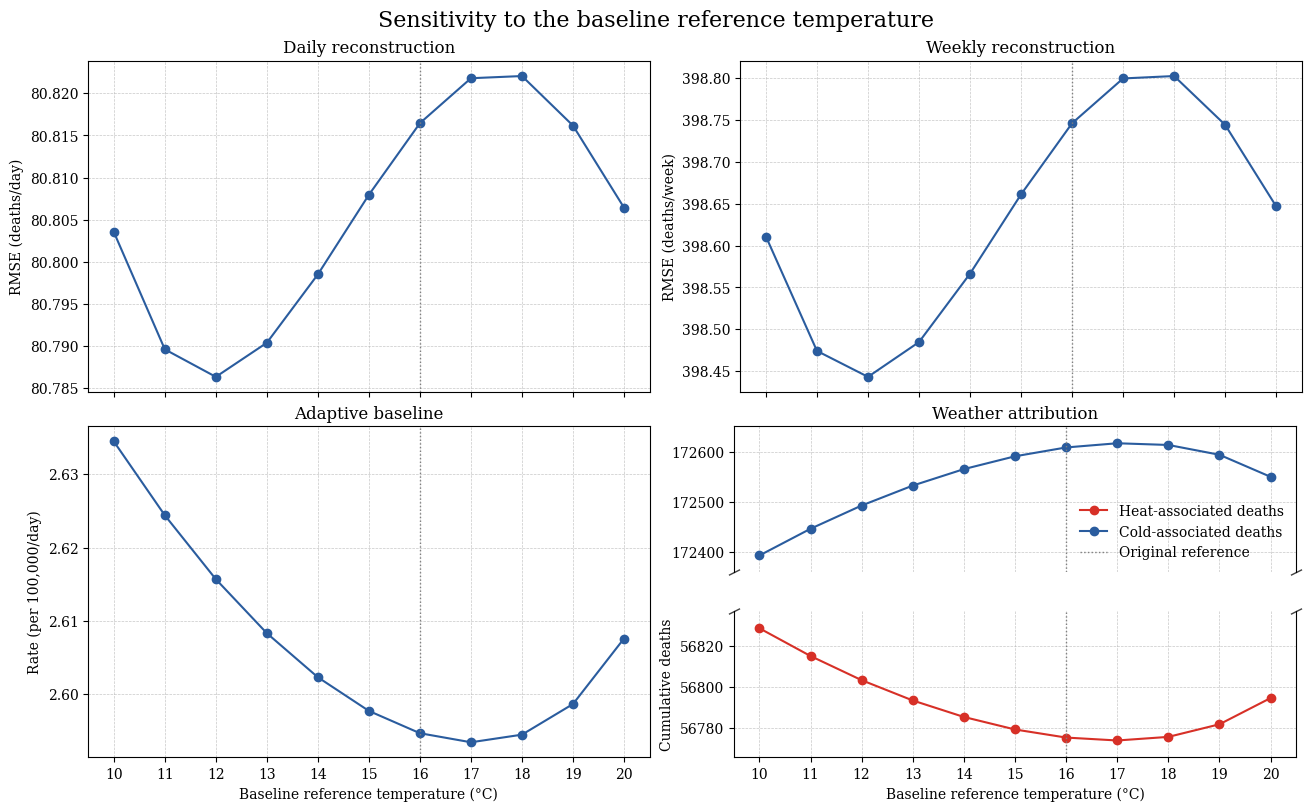

In [5]:
def plot_reference_series(ax, columns):
    for column in columns:
        color = "#D73027" if column.startswith("Heat") else "#2A5C9E"
        ax.plot(reference_results.index, reference_results[column],
                color=color, marker="o", linewidth=1.5, label=column)
    ax.axvline(16, color="0.5", linestyle=":", linewidth=1, label="Original reference")
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.7)


with plt.rc_context({"font.family": "DejaVu Serif", "axes.axisbelow": True}):
    fig = plt.figure(figsize=(13, 8), layout="constrained")
    grid = fig.add_gridspec(2, 2)
    panels = [
        ("Daily RMSE (deaths/day)", "Daily reconstruction", "RMSE (deaths/day)"),
        ("Weekly RMSE (deaths/week)", "Weekly reconstruction", "RMSE (deaths/week)"),
        ("Baseline rate (per 100,000/day)", "Adaptive baseline", "Rate (per 100,000/day)"),
    ]
    shared_x = None
    for index, (column, title, ylabel) in enumerate(panels):
        ax = fig.add_subplot(grid[index // 2, index % 2], sharex=shared_x)
        if shared_x is None:
            shared_x = ax
        plot_reference_series(ax, [column])
        ax.set(title=title, ylabel=ylabel)
        if index < 2:
            ax.tick_params(labelbottom=False)
        else:
            ax.set_xlabel("Baseline reference temperature (°C)")

    weather = ["Heat-associated deaths", "Cold-associated deaths"]
    ranges = sorted((reference_results[column].min(), reference_results[column].max())
                    for column in weather)
    gap = ranges[1][0] - ranges[0][1]
    if gap > 0:
        weather_grid = grid[1, 1].subgridspec(2, 1, hspace=0.07)
        upper = fig.add_subplot(weather_grid[0], sharex=shared_x)
        lower = fig.add_subplot(weather_grid[1], sharex=shared_x)
        for ax, (low, high) in zip((upper, lower), reversed(ranges)):
            padding = min(gap / 4, max(1, (high - low) * 0.15))
            plot_reference_series(ax, weather)
            ax.set_ylim(low - padding, high + padding)

        upper.spines["bottom"].set_visible(False)
        lower.spines["top"].set_visible(False)
        upper.tick_params(axis="x", bottom=False, labelbottom=False)
        for ax, edge in ((upper, 0), (lower, 1)):
            ax.plot([0, 1], [edge, edge], transform=ax.transAxes,
                    marker=[(-1, -0.5), (1, 0.5)], markersize=8,
                    linestyle="none", color="0.25", clip_on=False)
        upper.set_title("Weather attribution")
        lower.set_ylabel("Cumulative deaths")
        upper.legend(frameon=False)
        weather_axis = lower
    else:
        weather_axis = fig.add_subplot(grid[1, 1], sharex=shared_x)
        plot_reference_series(weather_axis, weather)
        weather_axis.set(title="Weather attribution", ylabel="Cumulative deaths")
        weather_axis.legend(frameon=False)

    weather_axis.set(xlabel="Baseline reference temperature (°C)", xticks=range(10, 21))
    fig.suptitle("Sensitivity to the baseline reference temperature", fontsize=16)
    plt.show()